## This notebook will describe the analysis for 
# Our comparitive analysis of the different population estimation approaches 

Rose Foster-Dyer   
Updated 02.09.2026

Refined Oct 13 2026
___ 

### Data types available (2024, 2025)
- SAR-derived breeding pairs (one count per year from midwinter) 
- SAR-derived individuals (one count per month through winter)
- VHR-derived abundance index using bayesian model (one per year from spring)
- VHR-derived abundance index using windchill model (one per year from spring) #these data were excluded
- chick counts (available for four sites)
- adult counts (available from just one site (Crozier))

I first plan to create a figure for each site, one panel per year (2024 and 2025) with all data sources included 

I also want to create a simple table showing the data available per type per year. 


I will also statistically compare the results produced through each method in another notebook. 

___

This paper will be prepared for Methods in Ecology and Evolution or something similar, and will be presented as the value of deploying a suite of observational tools to better elucidate population trends and trajectories

___ 

This will use methods described in:   
- Foster-Dyer et al. "Midwinter radar imaging establishes first breeding population baseline for the endangered emperor penguin" submitted to RSEC 
- LaRue et al. 2024 "Advances in remote sensing..." Proc B. 
- Foster-Dyer et al. 2026 "Evidence of emperor penguins sensitivity to sea ice fluctuations" Proc B. 
- Winterl et al. 2024 "Remote sensing and emperor penguins..." Nature Comms. 

In [24]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D


from scipy import stats
from scipy.optimize import minimize
from sklearn.utils import resample
import seaborn as sns


In [25]:
# Loading data 

INPUTPATH = "/mnt/c/Users/rfo37/OneDrive - University of Canterbury/Github/SAR_RossSea_compare/SAR_RossSea_compare/"

df_RossSea = pd.read_csv(os.path.join(INPUTPATH, "Data/RS_pops2425_combined.csv"))


In [26]:
df_RossSea.info()
df_RossSea.head()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   colony         155 non-null    str    
 1   site_id        155 non-null    str    
 2   type           155 non-null    str    
 3   date           152 non-null    str    
 4   month          152 non-null    float64
 5   day            152 non-null    float64
 6   year           155 non-null    int64  
 7   DOY            155 non-null    float64
 8   lat            155 non-null    float64
 9   lon            155 non-null    float64
 10  count          149 non-null    float64
 11  count_se       139 non-null    float64
 12  method         155 non-null    str    
 13  notes          25 non-null     str    
 14  phenology_est  101 non-null    str    
dtypes: float64(7), int64(1), str(7)
memory usage: 25.7 KB


,colony,site_id,type,date,month,day,year,DOY,lat,lon,count,count_se,method,notes,phenology_est
0,Crozier,CROZ,adults,21/11/2024,11.0,21.0,2024,325.0,-77.452742,169.275066,1075.0,NaN,adults,"Annie Schmidt, Grant Ballard",NaN
1,Crozier,CROZ,adults,22/11/2025,11.0,22.0,2025,326.0,-77.452742,169.275066,627.0,NaN,adults,"Annie Schmidt, Grant Ballard",NaN
2,Coulman,COUL,chicks,21/11/2024,11.0,21.0,2024,325.0,-73.350000,169.610000,21242.0,NaN,chicks,Jeong-Hoon Kim,NaN
3,Coulman,COUL,chicks,6/12/2025,12.0,6.0,2025,340.0,-73.350000,169.610000,6686.0,NaN,chicks,Jeong-Hoon Kim,NaN
4,Crozier,CROZ,chicks,21/11/2024,11.0,21.0,2024,325.0,-77.452742,169.275066,2773.0,NaN,chicks,"Annie Schmidt, Grant Ballard",NaN


In [27]:
# Convert the 'year' column to integers
df_RossSea['year'] = df_RossSea['year'].astype(int)


In [28]:
#creating categories for plotting
df_RossSea = df_RossSea.astype({
    'method': 'category',
    'type': 'category',
    'colony': 'category',
    'year': 'category', 
    'notes': 'category'
})

In [29]:
# Loop through your categorical columns
for col in ['colony', 'type', 'method', 'year', 'notes']:
    print(f"\nLevels in '{col}':")
    print(list(df_RossSea[col].cat.categories))


Levels in 'colony':
['Beaufort', 'Colbeck', 'Coulman', 'Crozier', 'Franklin', 'Roget', 'Washington']

Levels in 'type':
['abundance index', 'adults', 'breeding pairs', 'chicks', 'individuals']

Levels in 'method':
['SAR', 'SAR-bp', 'VHR-bayes', 'VHR-rho', 'adults', 'chicks']

Levels in 'year':
[2024, 2025]

Levels in 'notes':
['Annie Schmidt, Grant Ballard', 'Jeong-Hoon Kim ', 'birds too dispersed to quantify', 'colony', 'combined', 'iceberg', 'no VHR image acquired in 2024, doy taken from 2025', 'no birds visible']


## Different counts at Coulman in 2025 

I have quantified both the group of birds up on the iceberg as well as those down at the colony, and then i have also quantified the total combined number.   

We will move forward with only the combined value, so need to subset that out and proceed with that df as the one to plot.   


But there is value in the different number for each group, and we will explore those values as a case study and the differences in chicks, sar-bp, and vhr

In [30]:
# Exclude 'iceberg' and 'colony' data from 'notes' row in Coulman 2025 data and move forward with a dataset without those datapoint, to be added back in for other parts of the analysis. 

# We need to identify the rows that are coulman, 2025 and VHR-bayes
condition_exclude = (df_RossSea['notes'] == 'colony') | (df_RossSea['notes'] == 'iceberg')

df_RossSea = df_RossSea[#condition_include & 
    ~condition_exclude]

print(df_RossSea)

         colony site_id             type        date  month   day  year  \
0       Crozier    CROZ           adults  21/11/2024   11.0  21.0  2024   
1       Crozier    CROZ           adults  22/11/2025   11.0  22.0  2025   
2       Coulman    COUL           chicks  21/11/2024   11.0  21.0  2024   
3       Coulman    COUL           chicks   6/12/2025   12.0   6.0  2025   
4       Crozier    CROZ           chicks  21/11/2024   11.0  21.0  2024   
..          ...     ...              ...         ...    ...   ...   ...   
150    Franklin    FRAN  abundance index  24/10/2025   10.0  24.0  2025   
151       Roget    ROGE  abundance index  22/10/2025   10.0  22.0  2025   
152       Roget    ROGE  abundance index  11/10/2024   10.0  11.0  2024   
153  Washington    WASH  abundance index  27/10/2024   10.0  27.0  2024   
154  Washington    WASH  abundance index   1/11/2025   11.0   1.0  2025   

       DOY        lat         lon     count     count_se   method  \
0    325.0 -77.452742  169.275

# Creating a figure that shows the year long cycle of population change for Ross Sea colonies 


In [31]:
## Creating a summary table for the totals from each method: 

total_summary = (
    df_RossSea
    .groupby(['method', 'year'])
    .agg(
        total_population=('count', 'sum'),
        n_colonies=('colony', 'nunique')
    )
    .reset_index()
)

total_summary

,method,year,total_population,n_colonies
0,SAR,2024,543556.65000,5
1,SAR,2025,600709.79000,7
2,SAR-bp,2024,39358.60000,5
3,SAR-bp,2025,62999.48000,7
4,VHR-bayes,2024,52505.87618,7
5,VHR-bayes,2025,51885.18000,7
6,VHR-rho,2024,167174.65000,3
7,VHR-rho,2025,334363.62000,7
8,adults,2024,1075.00000,1
9,adults,2025,627.00000,1


In [32]:
# 1. Peak SAR value for each colony-year
sar_peak = (
    df_RossSea[df_RossSea['method'] == 'SAR']
    .groupby(['colony', 'year'], as_index=False)['count']
    .max()
    .assign(method='SAR')
)

# 2. All non-SAR observations
other_methods = (
    df_RossSea[df_RossSea['method'] != 'SAR']
    [['method', 'colony', 'year', 'count']]
    .copy()
)

# 3. Combine them
colony_year_summary = pd.concat(
    [sar_peak[['method', 'colony', 'year', 'count']],
     other_methods],
    ignore_index=True
)

# 4. Calculate summary statistics across colonies
summary_table = (
    colony_year_summary
    .groupby(['method', 'year'])
    .agg(
        n_colonies=('colony', 'nunique'),
        total_population=('count', 'sum'),
        mean=('count', 'mean'),
        median=('count', 'median'),
        sd=('count', 'std'),
        minimum=('count', 'min'),
        maximum=('count', 'max')
    )
    .reset_index()
)

# 5. Create a range column
summary_table['range'] = (
    summary_table['minimum'].round(0).astype(int).astype(str)
    + '–' +
    summary_table['maximum'].round(0).astype(int).astype(str)
)

# 6. Keep the columns in a sensible reporting order
summary_table = summary_table[
    ['method', 'year', 'n_colonies', 'total_population',
     'mean', 'median', 'sd', 'range']
]

summary_table

,method,year,n_colonies,total_population,mean,median,sd,range
0,SAR,2024,5,82627.49000,16525.498000,14988.76,8947.103658,5186–29189
1,SAR,2025,7,115801.58000,16543.082857,9882.92,14720.593319,632–40271
2,SAR-bp,2024,5,39358.60000,7871.720000,5261.45,5563.396665,2350–16376
3,SAR-bp,2025,7,62999.48000,8999.925714,7252.01,7695.622738,564–21418
4,VHR-bayes,2024,7,52505.87618,7500.839454,4382.11,8220.828087,293–23822
5,VHR-bayes,2025,7,51885.18000,7412.168571,4049.60,8187.126498,274–23619
6,VHR-rho,2024,3,167174.65000,55724.883333,46595.07,34191.091954,27025–93554
7,VHR-rho,2025,7,334363.62000,47766.231429,21047.74,57381.461091,1198–160988
8,adults,2024,1,1075.00000,1075.000000,1075.00,NaN,1075–1075
9,adults,2025,1,627.00000,627.000000,627.00,NaN,627–627


## Simple exploratory plot 



## We need to exclude the VHR-rho data 

These data are those that used the huddle areas derived from high resolution optical imagery along with the Winterl et al. 2024 windchill model and they produce non sensical data.   

This is becuase the rho values vary between 4.275 and 6.059 birds per m2, which when individual penguins are included on the ice, not huddled, creates a vast overestimation about how many birds there are in each meter. This makes sense when considering densley aggregated huddles, but our VHR analysis also captures more loosely aggregated birds 



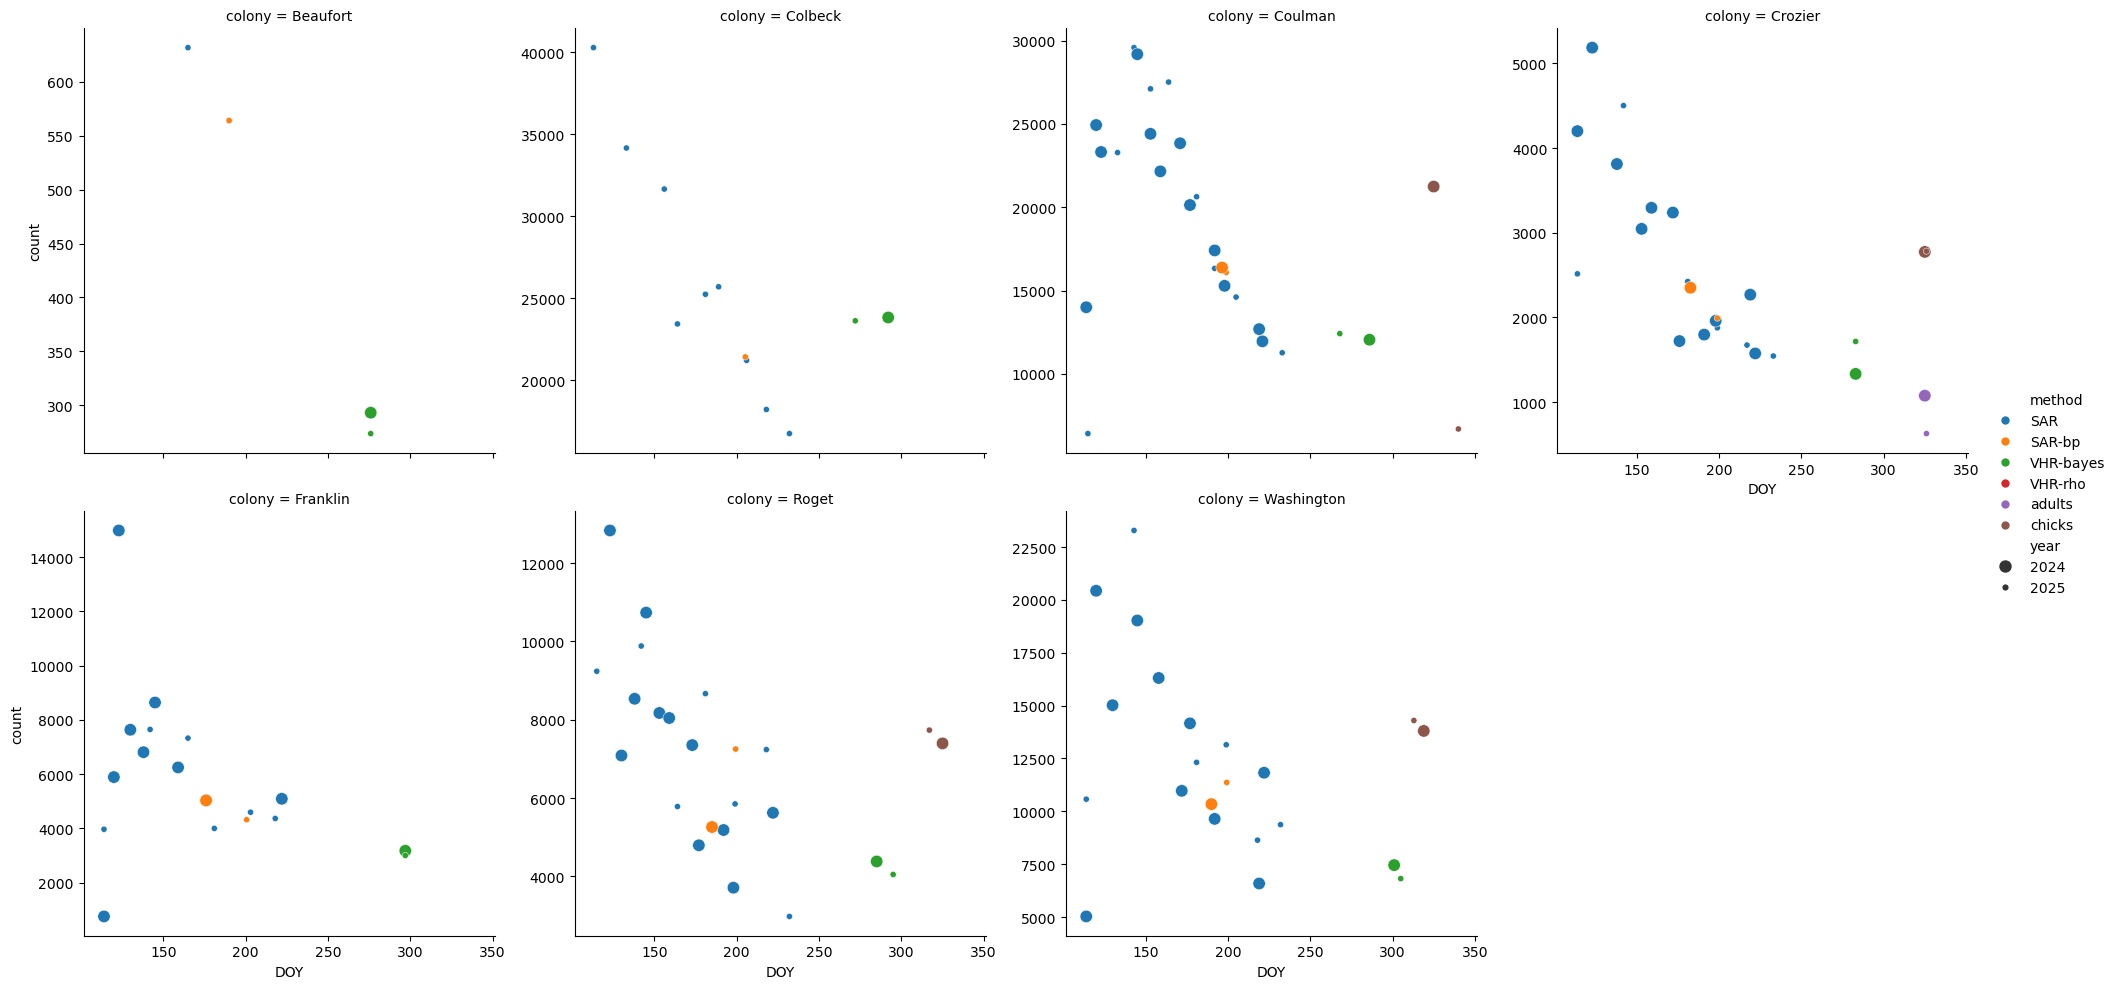

In [33]:
# Exclude a level from method 

filtered_df_RS = df_RossSea[df_RossSea["method"] != "VHR-rho"]

# Creates a row of separate subplots for each colony
sns.relplot(
    data=filtered_df_RS, 
    x='DOY', 
    y='count', 
    col='colony',   # Separate subplots by colony
    hue='method',   # Distinct colors for each method
    kind='scatter',  # Can change to 'line' if needed
    col_wrap=4, 
    size = 'year', 
    sizes = (20, 80),
    facet_kws=dict(sharey=False))

plt.show()

## Let's try with matplotlib, so we can include both line and points on one plot

In [34]:
# Exclude a level from method, and create new dataframe with data from each year 

filtered_df_RS = df_RossSea[df_RossSea["method"] != "VHR-rho"]
filtered_df_RS24 = filtered_df_RS[filtered_df_RS["year"] != 2025]
filtered_df_RS25 = filtered_df_RS[filtered_df_RS["year"] != 2024]

## Using different markers for different years

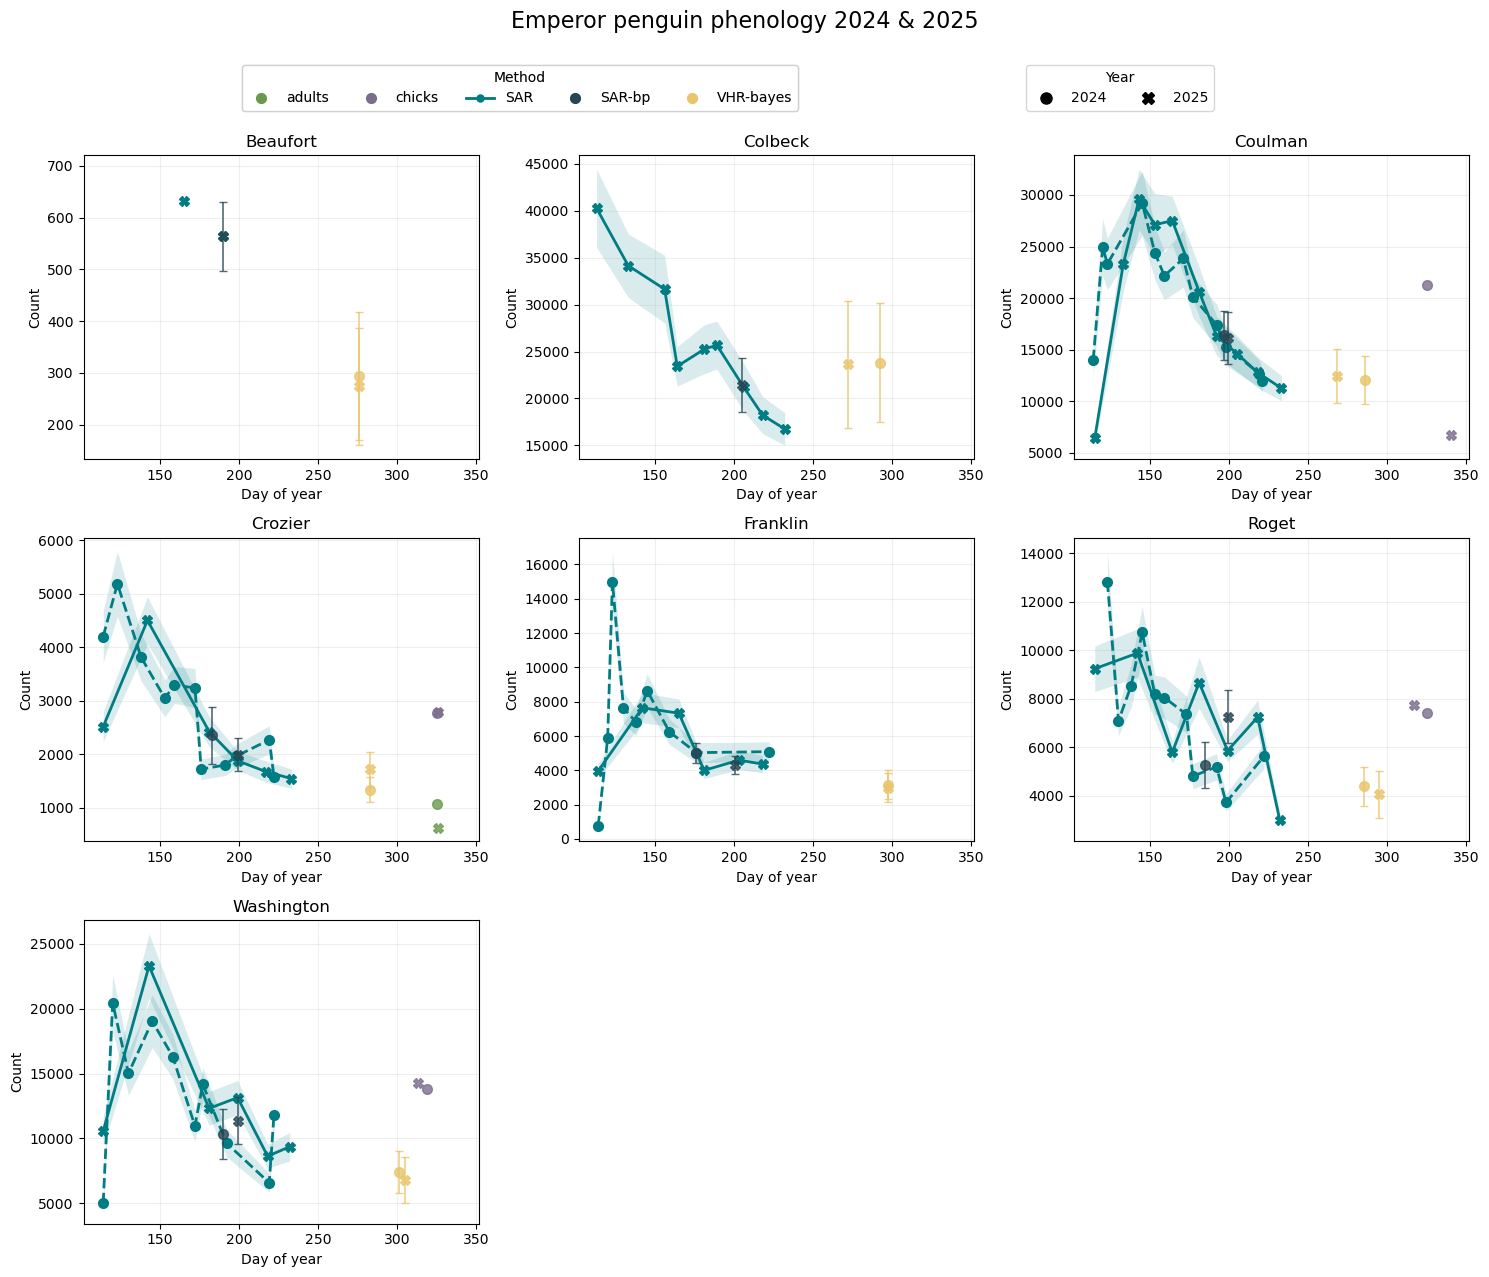

In [35]:
# Get categories
#colonies = filtered_df_RS["colony"].dropna().unique()
colonies = sorted(filtered_df_RS["colony"].dropna().unique()) #order by alphabet
methods = filtered_df_RS["method"].dropna().unique()

# Work out panel layout
n_cols = 3
n_rows = int(np.ceil(len(colonies) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows),
    sharex=True,
    sharey=False
)

years = sorted(filtered_df_RS["year"].dropna().unique())

year_markers = {
    2024: "o",
    2025: "X"
}

year_linestyles = {
    2024: "--",
    2025: "-"
}

# Flatten axes so they are easy to loop through
axes = np.atleast_1d(axes).flatten()

# Assign one colour to each method
#colors = plt.cm.tab10(np.linspace(0, 1, len(methods)))
#method_colors = dict(zip(methods, colors))

method_colors = {
    "SAR": "#007C83",        # deep teal
    "SAR-bp": "#264653",     # dark navy
    "VHR-bayes": "#E9C46A",  # golden ochre
    "VHR-rho": "#E76F51",    # coral
    "chicks": "#7B6D8D",     # soft purple
    "adults": "#6A994E"      # sage green
}


# Plot each colony in its own panel
# Plot each colony in its own panel
for ax, colony in zip(axes, colonies):

    df_colony = filtered_df_RS[filtered_df_RS["colony"] == colony]

    for method in methods:

        for year in years:

            df_method_year = df_colony[
                (df_colony["method"] == method) &
                (df_colony["year"] == year)
            ].copy()

            # SAR = line
            if method == "SAR":

                # Sort by day of year so the line connects points correctly
                df_method_year = df_method_year.sort_values("DOY")

                ax.fill_between(
                    df_method_year["DOY"],
                    df_method_year["count"] - df_method_year["count_se"],
                    df_method_year["count"] + df_method_year["count_se"],
                    color=method_colors[method],
                    alpha=0.15,
                    linewidth=0
                )
                ax.plot(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    color=method_colors[method],
                    linewidth=2,
                     linestyle=year_linestyles[year],
                    marker=year_markers[year],
                    markersize=7,
                    label=f"{method} {year}"
                )

            # All other methods = scatter
            #else:

            # All other methods = points + SE bars
            else:

                ax.errorbar(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    yerr=df_method_year["count_se"],
                    fmt=year_markers[year],
                    color=method_colors[method],
                    markersize=7,
                    capsize=3,
                    elinewidth=1.2,
                    markeredgewidth=1,
                    alpha=0.8,
                    linestyle="none",
                    label=f"{method} {year}"
                )

    ax.set_title(colony)
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelbottom=True)

# Remove unused panels
for ax in axes[len(colonies):]:
    ax.remove()

# One shared legend
handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:

        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    handles.append(handle)


# Method legend — colour
method_handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:
        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    method_handles.append(handle)


# Year legend — marker

year_handles = []

for year in years:

    handle = plt.Line2D(
        [0], [0],
        marker=year_markers[year],
        linestyle="",
        color="black",
        markersize=8,
        label=str(year)
    )

    year_handles.append(handle)


# Add legends

legend1 = fig.legend(
    handles=method_handles,
    title="Method",
    loc="upper center",
    bbox_to_anchor=(0.35, 1.02),
    ncol=len(methods)
)

legend2 = fig.legend(
    handles=year_handles,
    title="Year",
    loc="upper center",
    bbox_to_anchor=(0.75, 1.02),
    ncol=len(years)
)

fig.add_artist(legend1)

fig.suptitle(
    "Emperor penguin phenology 2024 & 2025",
    fontsize=16,
    y=1.06
)

plt.tight_layout()

plt.savefig(os.path.join(INPUTPATH, "Results/all_colonies_RS2425.png"),
            bbox_inches="tight", dpi=600)


plt.show()

____ 

## Recreating above plots but with individual years and combined with se bars and ribbons and new colours 

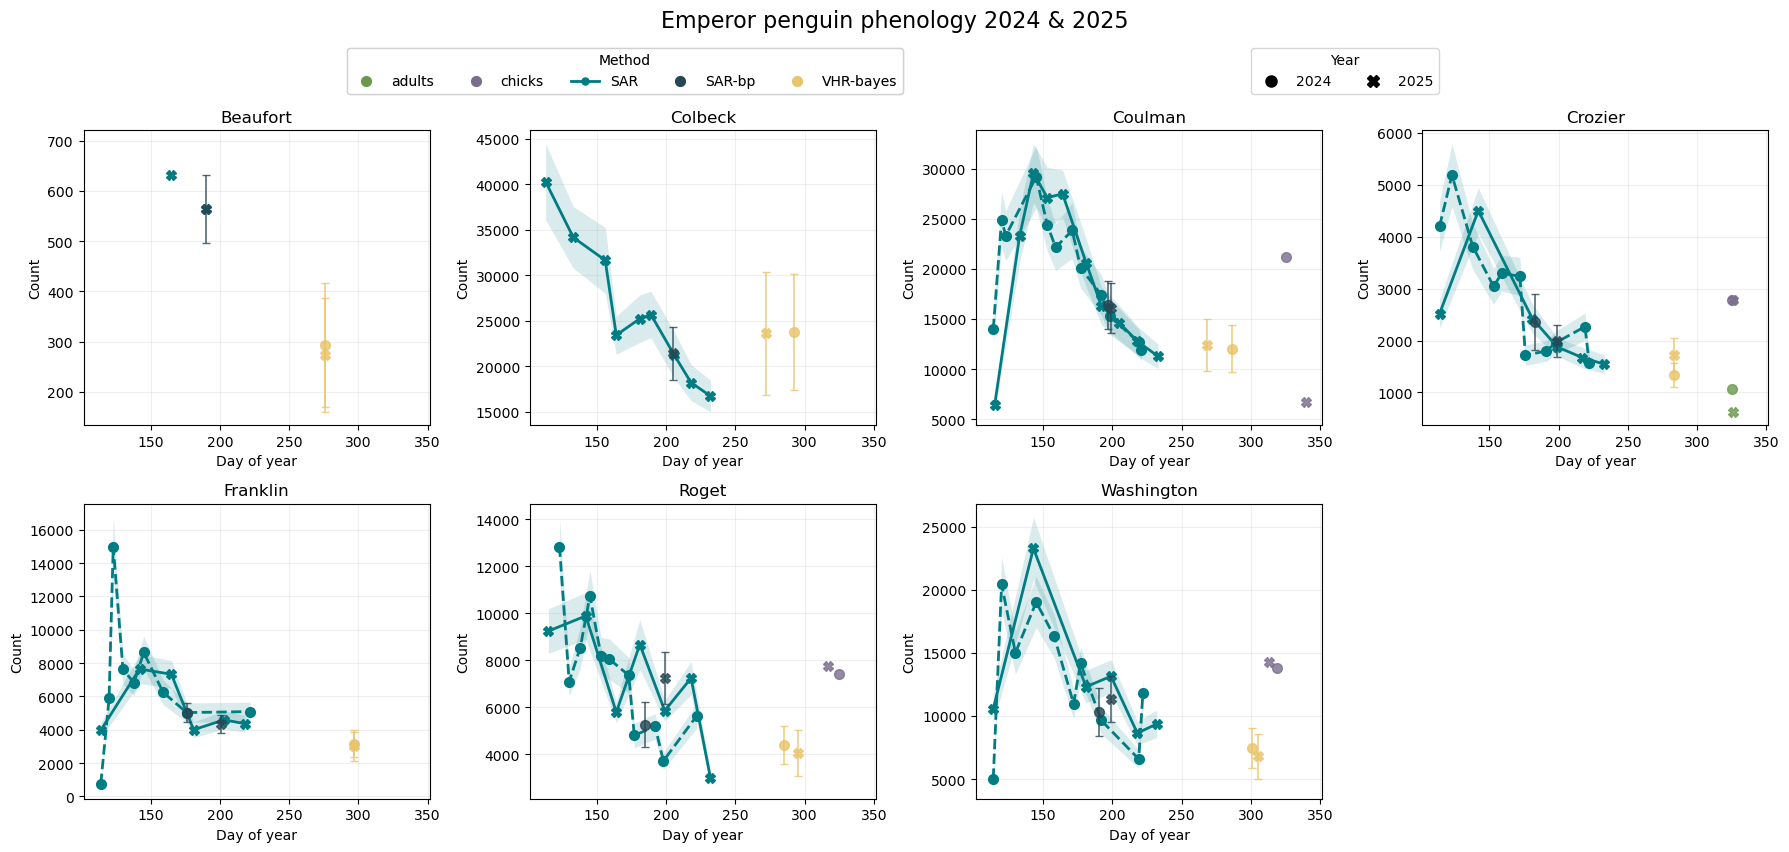

In [36]:
## Let's see if we can put it over 2 rows, rather than 3 

# Get categories
#colonies = filtered_df_RS["colony"].dropna().unique()
colonies = sorted(filtered_df_RS["colony"].dropna().unique()) #order by alphabet
methods = filtered_df_RS["method"].dropna().unique()

# Work out panel layout
n_cols = 4
n_rows = int(np.ceil(len(colonies) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows),
    sharex=True,
    sharey=False
)

years = sorted(filtered_df_RS["year"].dropna().unique())

year_markers = {
    2024: "o",
    2025: "X"
}

year_linestyles = {
    2024: "--",
    2025: "-"
}

# Flatten axes so they are easy to loop through
axes = np.atleast_1d(axes).flatten()

# Assign one colour to each method
#colors = plt.cm.tab10(np.linspace(0, 1, len(methods)))
#method_colors = dict(zip(methods, colors))

method_colors = {
    "SAR": "#007C83",        # deep teal
    "SAR-bp": "#264653",     # dark navy
    "VHR-bayes": "#E9C46A",  # golden ochre
    "VHR-rho": "#E76F51",    # coral
    "chicks": "#7B6D8D",     # soft purple
    "adults": "#6A994E"      # sage green
}


# Plot each colony in its own panel
# Plot each colony in its own panel
for ax, colony in zip(axes, colonies):

    df_colony = filtered_df_RS[filtered_df_RS["colony"] == colony]

    for method in methods:

        for year in years:

            df_method_year = df_colony[
                (df_colony["method"] == method) &
                (df_colony["year"] == year)
            ].copy()

            # SAR = line
            if method == "SAR":

                # Sort by day of year so the line connects points correctly
                df_method_year = df_method_year.sort_values("DOY")

                ax.fill_between(
                    df_method_year["DOY"],
                    df_method_year["count"] - df_method_year["count_se"],
                    df_method_year["count"] + df_method_year["count_se"],
                    color=method_colors[method],
                    alpha=0.15,
                    linewidth=0
                )
                ax.plot(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    color=method_colors[method],
                    linewidth=2,
                     linestyle=year_linestyles[year],
                    marker=year_markers[year],
                    markersize=7,
                    label=f"{method} {year}"
                )

            # All other methods = scatter
            #else:

            # All other methods = points + SE bars
            else:

                ax.errorbar(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    yerr=df_method_year["count_se"],
                    fmt=year_markers[year],
                    color=method_colors[method],
                    markersize=7,
                    capsize=3,
                    elinewidth=1.2,
                    markeredgewidth=1,
                    alpha=0.8,
                    linestyle="none",
                    label=f"{method} {year}"
                )

    ax.set_title(colony)
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelbottom=True)

# Remove unused panels
for ax in axes[len(colonies):]:
    ax.remove()

# One shared legend
handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:

        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    handles.append(handle)


# Method legend — colour
method_handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:
        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    method_handles.append(handle)


# Year legend — marker

year_handles = []

for year in years:

    handle = plt.Line2D(
        [0], [0],
        marker=year_markers[year],
        linestyle="",
        color="black",
        markersize=8,
        label=str(year)
    )

    year_handles.append(handle)


# Add legends

legend1 = fig.legend(
    handles=method_handles,
    title="Method",
    loc="upper center",
    bbox_to_anchor=(0.35, 1.02),
    ncol=len(methods)
)

legend2 = fig.legend(
    handles=year_handles,
    title="Year",
    loc="upper center",
    bbox_to_anchor=(0.75, 1.02),
    ncol=len(years)
)

fig.add_artist(legend1)

fig.suptitle(
    "Emperor penguin phenology 2024 & 2025",
    fontsize=16,
    y=1.06
)

plt.tight_layout()

plt.savefig(os.path.join(INPUTPATH, "Results/all_colonies_RS2425_v2.png"),
            bbox_inches="tight", dpi=600)


plt.show()

## Removing the other data types and keeping only the attrition data

#### Changing the colours for the two years and removing beaufort island as no attrition data 


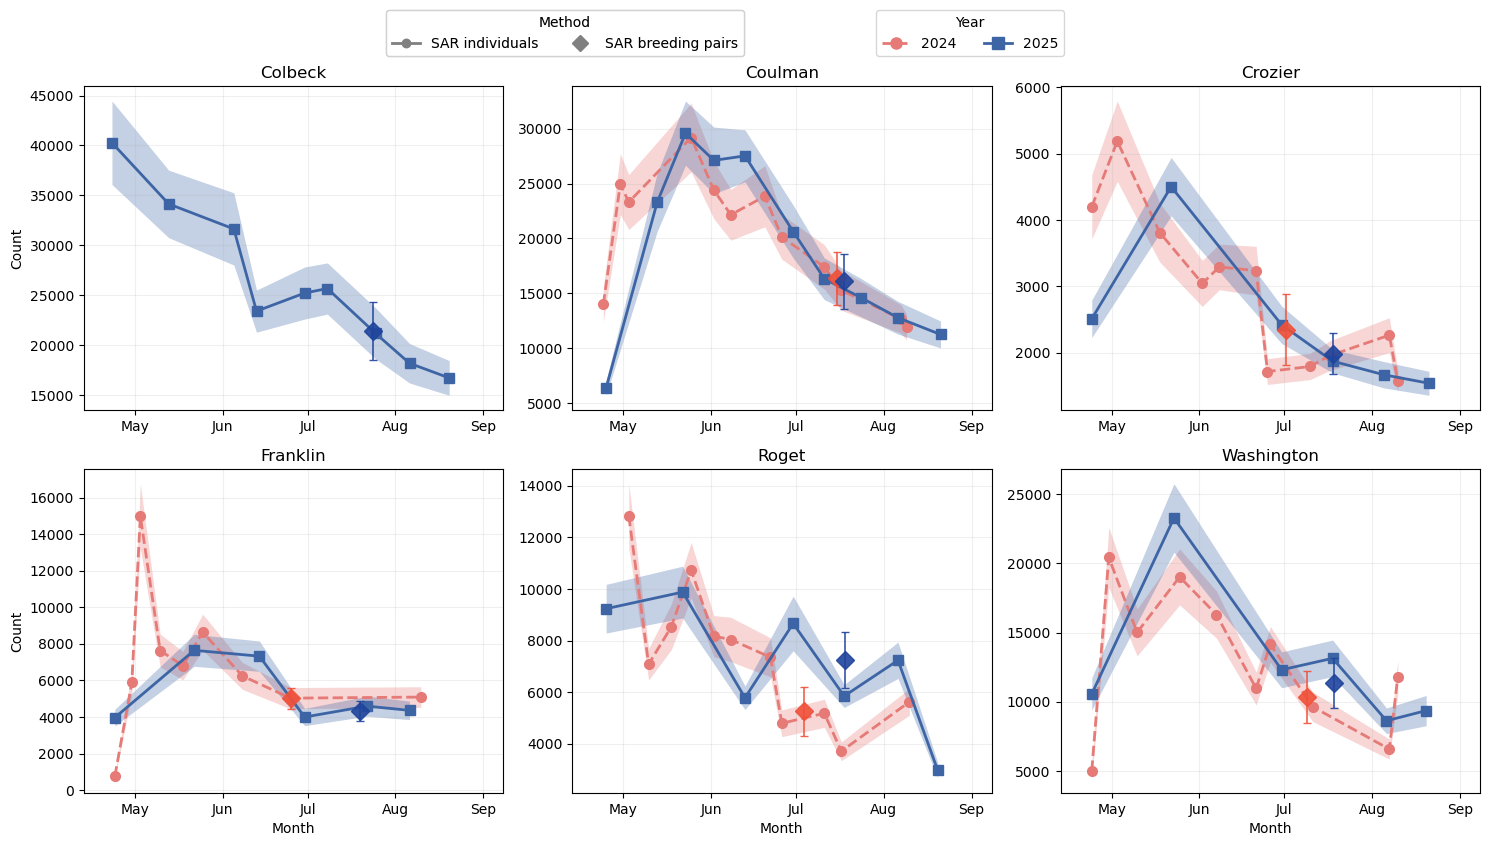

In [40]:
# Keep only SAR methods and drop Beaufort Island
keep_methods = ["SAR", "SAR-bp"]

plot_df = filtered_df_RS[
    filtered_df_RS["method"].isin(keep_methods)
    & ~filtered_df_RS["colony"].str.contains("Beaufort", case=False, na=False)
].copy()

plot_df["year"] = plot_df["year"].astype(int)

# Get categories
colonies = sorted(plot_df["colony"].dropna().unique())  # alphabetical
methods = [m for m in keep_methods if m in plot_df["method"].unique()]
years = sorted(plot_df["year"].dropna().unique())

# Year styling: change these to whatever you like
year_colors = {
     2024: "#E57A77",  # dark coral
     2025: "#3D65A5",  # dark teal
}

# Darker shade of each year colour for the breeding pairs points
year_colors_bp = {
    2024: "#F05039", 
    2025: "#1F449C",  
}

year_linestyles = {2024: "--", 2025: "-"}

# Markers by method and year
markers = {
    "SAR":    {2024: "o", 2025: "s"},  # circle, square
    "SAR-bp": {2024: "D", 2025: "D"},  # diamond for breeding pairs
}

# Month tick positions (first day of each month, non-leap year)
month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

doy_min, doy_max = plot_df["DOY"].min(), plot_df["DOY"].max()
ticks = [(d, l) for d, l in zip(month_starts, month_labels)
         if doy_min - 15 <= d <= doy_max + 15]

# Work out panel layout
n_cols = 3
n_rows = int(np.ceil(len(colonies) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows),
    sharex=True,
    sharey=False
)
axes = np.atleast_1d(axes).flatten()

# Plot each colony in its own panel
for i, (ax, colony) in enumerate(zip(axes, colonies)):

    df_colony = plot_df[plot_df["colony"] == colony]

    for method in methods:
        for year in years:

            df_method_year = df_colony[
                (df_colony["method"] == method)
                & (df_colony["year"] == year)
            ].sort_values("DOY")

            if df_method_year.empty:
                continue

            # SAR individuals = line with SE band
            if method == "SAR":

                ax.fill_between(
                    df_method_year["DOY"],
                    df_method_year["count"] - df_method_year["count_se"],
                    df_method_year["count"] + df_method_year["count_se"],
                    color=year_colors[year],
                    alpha=0.3,
                    linewidth=0
                )
                ax.plot(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    color=year_colors[year],
                    linewidth=2,
                    linestyle=year_linestyles[year],
                    marker=markers["SAR"][year],
                    markersize=7,
                    label=f"SAR {year}"
                )

            # SAR breeding pairs = point with SE bar
            else:

                ax.errorbar(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    yerr=df_method_year["count_se"],
                    fmt=markers["SAR-bp"][year],
                    color=year_colors_bp[year],
                    markersize=9,
                    capsize=3,
                    elinewidth=1.2,
                    markeredgewidth=1,
                    alpha=0.9,
                    linestyle="none",
                    label=f"SAR-bp {year}"
                )

    ax.set_title(colony)
    # Only label panels with no panel directly below
    if i + n_cols >= len(colonies):
        ax.set_xlabel("Month")
        # Only label panels in the first column
    if i % n_cols == 0:
        ax.set_ylabel("Count")
    ax.set_xticks([d for d, _ in ticks])
    ax.set_xticklabels([l for _, l in ticks])
    ax.set_xlim(doy_min - 10, doy_max + 10)
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelbottom=True)

# Remove unused panels
for ax in axes[len(colonies):]:
    ax.remove()

# Method legend (shape, in neutral grey)
method_handles = [
    plt.Line2D([0], [0], color="grey", linewidth=2,
               marker="o", markersize=6, label="SAR individuals"),
    plt.Line2D([0], [0], color="grey", linestyle="",
               marker="D", markersize=8, label="SAR breeding pairs"),
]

# Year legend (colour, line style and marker)
year_handles = [
    plt.Line2D([0], [0],
               color=year_colors[year],
               linestyle=year_linestyles[year],
               linewidth=2,
               marker=markers["SAR"][year],
               markersize=8,
               label=str(year))
    for year in years
]

legend1 = fig.legend(
    handles=method_handles,
    title="Method",
    loc="upper center",
    bbox_to_anchor=(0.38, 1.06),
    ncol=len(method_handles)
)

legend2 = fig.legend(
    handles=year_handles,
    title="Year",
    loc="upper center",
    bbox_to_anchor=(0.65, 1.06),
    ncol=len(years)
)

fig.add_artist(legend1)

#fig.suptitle(
#    "Emperor penguin SAR counts through the season, 2024 & 2025",
#    fontsize=16,
#    y=1.06
#)

plt.tight_layout()

plt.savefig(
    os.path.join(INPUTPATH, "Results/all_colonies_RS2425_SARonly_v2.png"),
    bbox_inches="tight",
    dpi=600
)

plt.show()

____ 

## Adding uncertainty ribbon for each estimate 

Using count_se column 

## ONLY 2024 DATA WITH NO VHR-RHO

We have also removd Colbeck and Beaufort as they have no data other than the VHR estimate

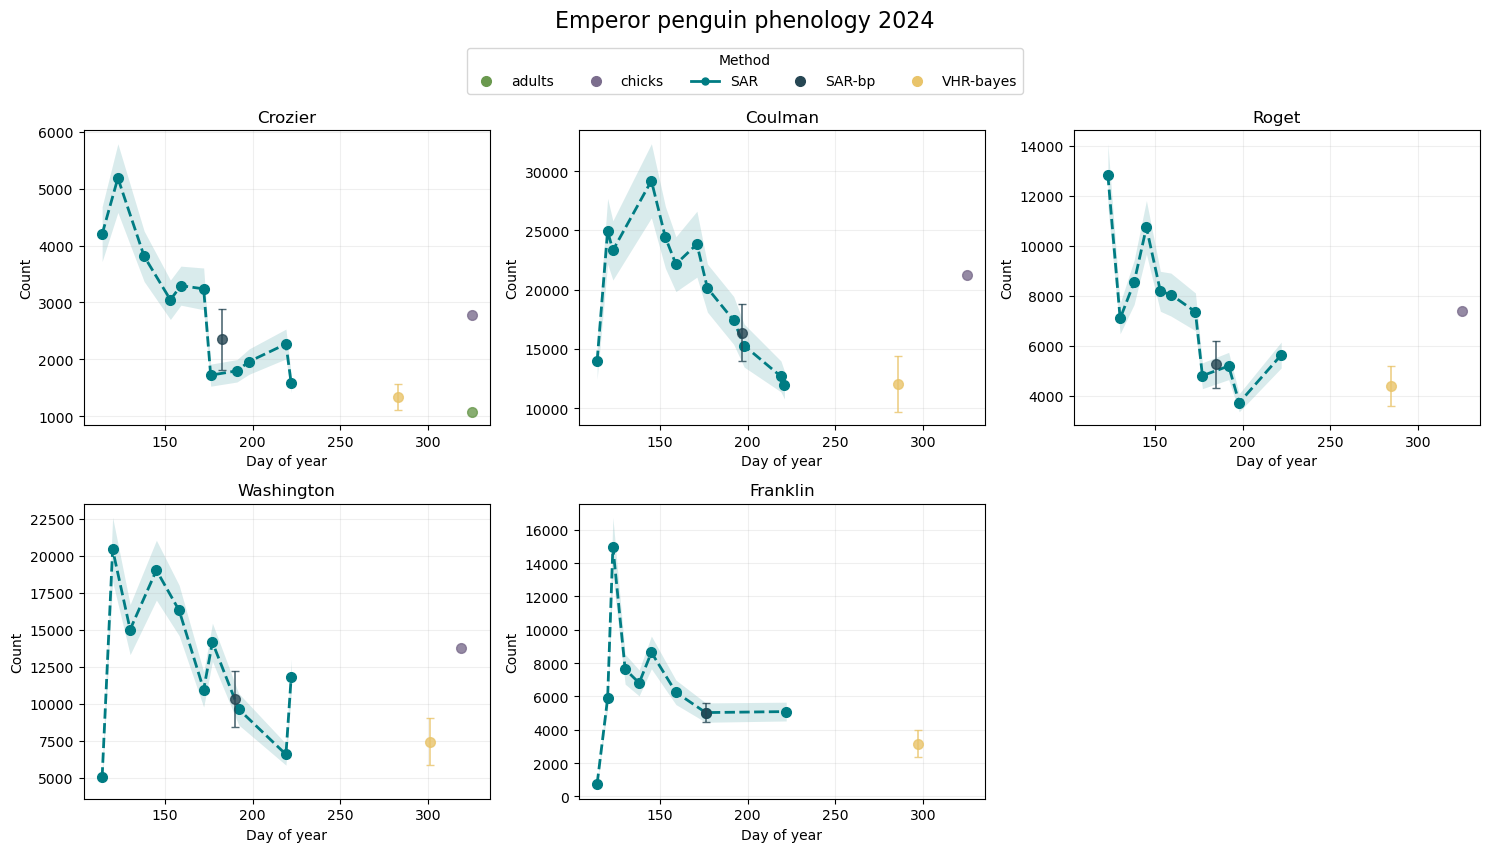

In [38]:
# Get categories

exclude_colonies = ["Colbeck", "Beaufort"]

# Keep only colonies we want to plot
colonies = [
    colony for colony in filtered_df_RS24["colony"].dropna().unique()
    if colony not in exclude_colonies
]

#colonies = filtered_df_RS["colony"].dropna().unique()
#colonies = sorted(filtered_df_RS["colony"].dropna().unique()) #order by alphabet
methods = filtered_df_RS24["method"].dropna().unique()

# Work out panel layout
n_cols = 3
n_rows = int(np.ceil(len(colonies) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows),
    sharex=True,
    sharey=False
)

# Flatten axes so they are easy to loop through
axes = np.atleast_1d(axes).flatten()

# Assign one colour to each method
#colors = plt.cm.tab10(np.linspace(0, 1, len(methods)))
#method_colors = dict(zip(methods, colors))

method_colors = {
    "SAR": "#007C83",        # deep teal
    "SAR-bp": "#264653",     # dark navy
    "VHR-bayes": "#E9C46A",  # golden ochre
    "VHR-rho": "#E76F51",    # coral
    "chicks": "#7B6D8D",     # soft purple
    "adults": "#6A994E"      # sage green
}


# Plot each colony in its own panel
# Plot each colony in its own panel
for ax, colony in zip(axes, colonies):

    df_colony = filtered_df_RS24[filtered_df_RS24["colony"] == colony]

    for method in methods:

        for year in years:

            df_method_year = df_colony[
                (df_colony["method"] == method) &
                (df_colony["year"] == year)
            ].copy()

            # SAR = line
            if method == "SAR":

                # Sort by day of year so the line connects points correctly
                df_method_year = df_method_year.sort_values("DOY")

                ax.fill_between(
                    df_method_year["DOY"],
                    df_method_year["count"] - df_method_year["count_se"],
                    df_method_year["count"] + df_method_year["count_se"],
                    color=method_colors[method],
                    alpha=0.15,
                    linewidth=0
                )
                ax.plot(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    color=method_colors[method],
                    linewidth=2,
                     linestyle=year_linestyles[year],
                    marker=year_markers[year],
                    markersize=7,
                    label=f"{method} {year}"
                )

            # All other methods = scatter
            #else:

            # All other methods = points + SE bars
            else:

                ax.errorbar(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    yerr=df_method_year["count_se"],
                    fmt=year_markers[year],
                    color=method_colors[method],
                    markersize=7,
                    capsize=3,
                    elinewidth=1.2,
                    markeredgewidth=1,
                    alpha=0.8,
                    linestyle="none",
                    label=f"{method} {year}"
                )

    ax.set_title(colony)
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelbottom=True)

# Remove unused panels
for ax in axes[len(colonies):]:
    ax.remove()

# One shared legend
handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:

        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    handles.append(handle)


# Method legend — colour
method_handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:
        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    method_handles.append(handle)


# Year legend — marker

year_handles = []

for year in years:

    handle = plt.Line2D(
        [0], [0],
        marker=year_markers[year],
        linestyle="",
        color="black",
        markersize=8,
        label=str(year)
    )

    year_handles.append(handle)


# Add legends
fig.legend(
    handles=handles,
    title="Method",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(methods)
)

fig.suptitle(
    "Emperor penguin phenology 2024",
    fontsize=16,
    y=1.06
)


plt.tight_layout()

plt.savefig(os.path.join(INPUTPATH, "Results/all_colonies_RS24_v2.png"),
            bbox_inches="tight", dpi=600)


plt.show()

## ONLY 2025 DATA PLOTTED

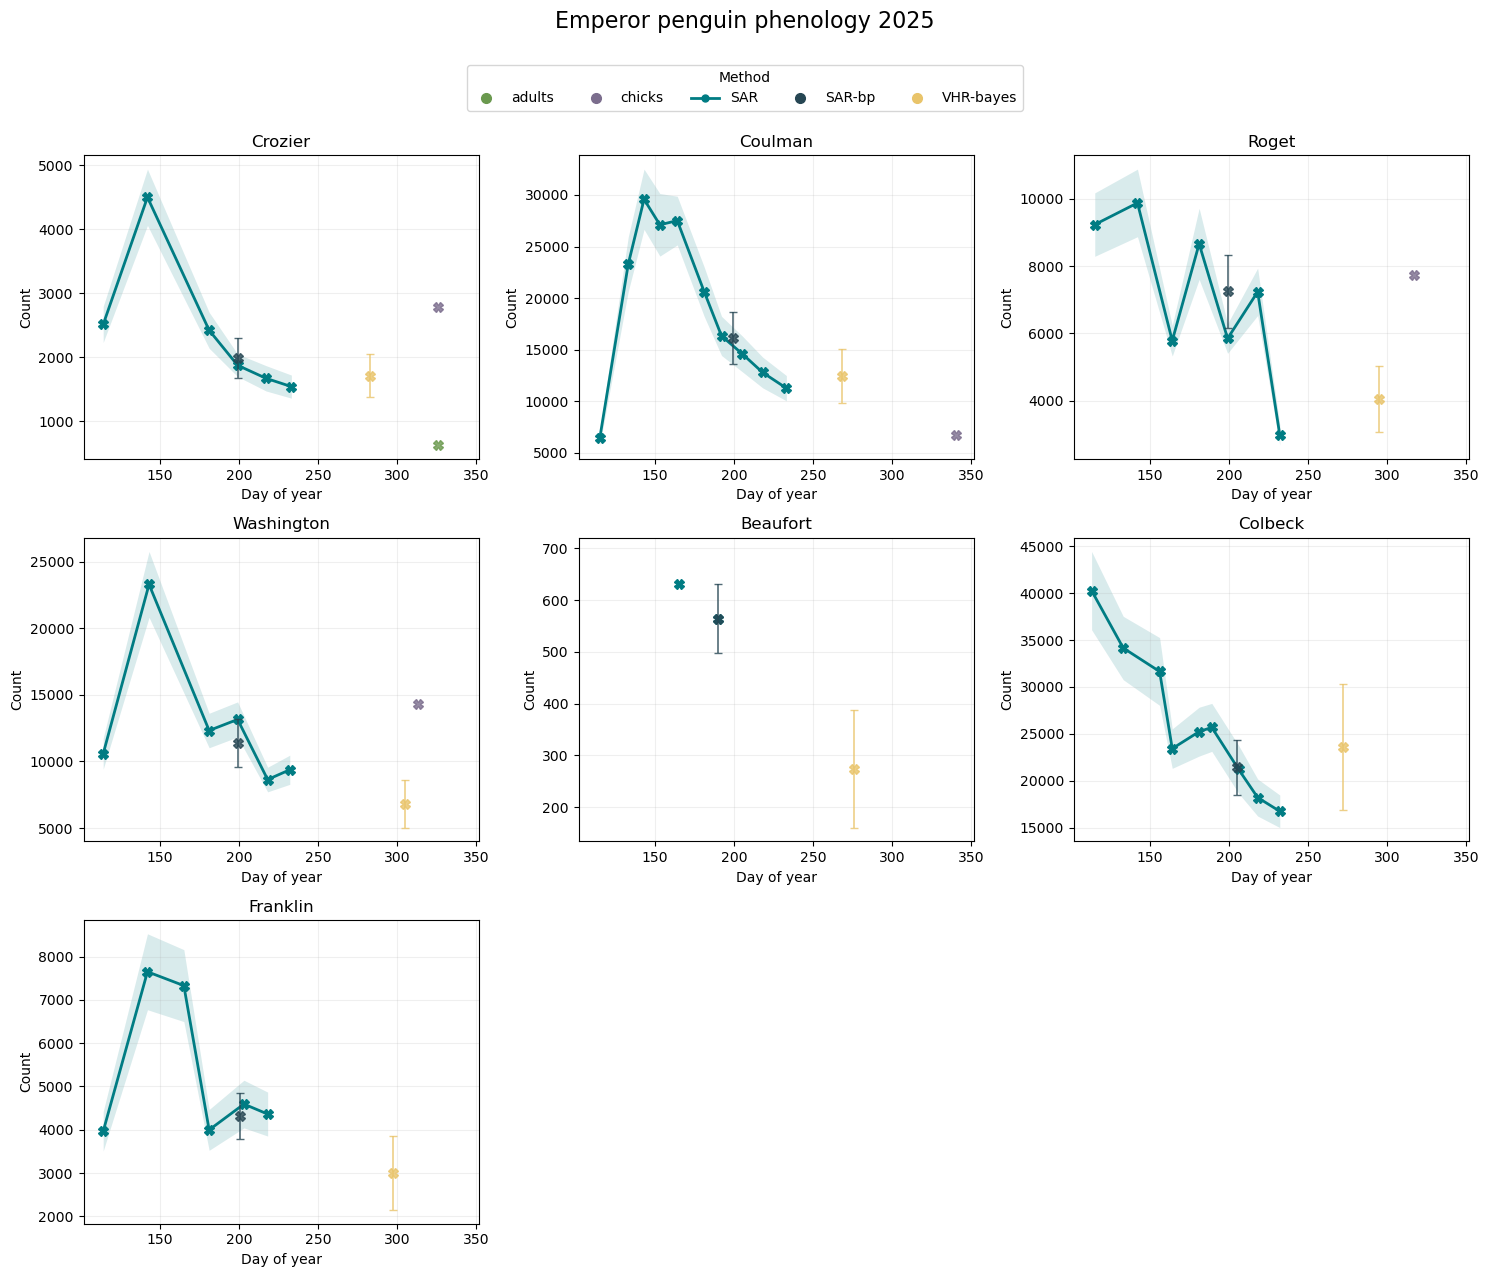

In [39]:
# ONLY 2025 DATA WITH NO VHR-RHO
# Get categories
colonies = filtered_df_RS25["colony"].dropna().unique()
methods = filtered_df_RS25["method"].dropna().unique()


# Work out panel layout
n_cols = 3
n_rows = int(np.ceil(len(colonies) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows),
    sharex=True,
    sharey=False
)

# Flatten axes so they are easy to loop through
axes = np.atleast_1d(axes).flatten()

# Assign one colour to each method
#colors = plt.cm.tab10(np.linspace(0, 1, len(methods)))
#method_colors = dict(zip(methods, colors))

method_colors = {
    "SAR": "#007C83",        # deep teal
    "SAR-bp": "#264653",     # dark navy
    "VHR-bayes": "#E9C46A",  # golden ochre
    "VHR-rho": "#E76F51",    # coral
    "chicks": "#7B6D8D",     # soft purple
    "adults": "#6A994E"      # sage green
}


# Plot each colony in its own panel
# Plot each colony in its own panel
for ax, colony in zip(axes, colonies):

    df_colony = filtered_df_RS25[filtered_df_RS25["colony"] == colony]

    for method in methods:

        for year in years:

            df_method_year = df_colony[
                (df_colony["method"] == method) &
                (df_colony["year"] == year)
            ].copy()

            # SAR = line
            if method == "SAR":

                # Sort by day of year so the line connects points correctly
                df_method_year = df_method_year.sort_values("DOY")

                ax.fill_between(
                    df_method_year["DOY"],
                    df_method_year["count"] - df_method_year["count_se"],
                    df_method_year["count"] + df_method_year["count_se"],
                    color=method_colors[method],
                    alpha=0.15,
                    linewidth=0
                )
                ax.plot(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    color=method_colors[method],
                    linewidth=2,
                     linestyle=year_linestyles[year],
                    marker=year_markers[year],
                    markersize=7,
                    label=f"{method} {year}"
                )

            # All other methods = scatter
            #else:

            # All other methods = points + SE bars
            else:

                ax.errorbar(
                    df_method_year["DOY"],
                    df_method_year["count"],
                    yerr=df_method_year["count_se"],
                    fmt=year_markers[year],
                    color=method_colors[method],
                    markersize=7,
                    capsize=3,
                    elinewidth=1.2,
                    markeredgewidth=1,
                    alpha=0.8,
                    linestyle="none",
                    label=f"{method} {year}"
                )

    ax.set_title(colony)
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.2)
    ax.tick_params(axis="x", labelbottom=True)

# Remove unused panels
for ax in axes[len(colonies):]:
    ax.remove()

# One shared legend
handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:

        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    handles.append(handle)


# Method legend — colour
method_handles = []

for method in methods:

    if method == "SAR":

        handle = plt.Line2D(
            [0], [0],
            color=method_colors[method],
            linewidth=2,
            marker="o",
            markersize=5,
            label=method
        )

    else:
        handle = plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=method_colors[method],
            markersize=7,
            label=method
        )

    method_handles.append(handle)


# Year legend — marker

year_handles = []

for year in years:

    handle = plt.Line2D(
        [0], [0],
        marker=year_markers[year],
        linestyle="",
        color="black",
        markersize=8,
        label=str(year)
    )

    year_handles.append(handle)


# Add legends
fig.legend(
    handles=handles,
    title="Method",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(methods)
)

fig.suptitle(
    "Emperor penguin phenology 2025",
    fontsize=16,
    y=1.06
)


plt.tight_layout()

plt.savefig(os.path.join(INPUTPATH, "Results/all_colonies_RS25_v2.png"),
            bbox_inches="tight", dpi=600)


plt.show()